# Introduction: Gradient Descent for Simple Linear Regression

In [17]:
import numpy as np
import matplotlib.pyplot as plt

## Understanding the dataset

In [18]:
from sklearn.datasets import make_regression

X,y = make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=13)

print(X.shape)
print(y.shape)

(100, 1)
(100,)


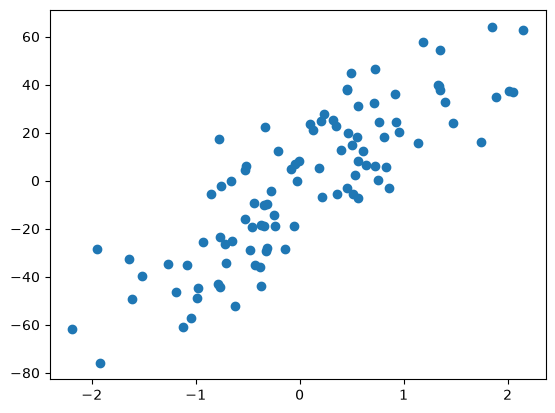

In [19]:
plt.scatter(X,y)
plt.show()

## Splitting the Data

In [20]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

print(X_train.shape)
print(X_test.shape)

(80, 1)
(20, 1)


## Training scikit learn regression algorithm with this data 

In [21]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train,y_train)

print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


## R2 Score of Linear Regression

In [22]:
from sklearn.metrics import r2_score

y_pred = lr.predict(X_test)

print(r2_score(y_test,y_pred))

0.6345158782661012


## Implementing Gradient Descent

In [23]:
class GDRegressor:

    def __init__(self,learning_rate,epochs):

        self.lr = learning_rate
        self.ep = epochs
        self.m = 0
        self.b = 0

        self.history = []


    def fit(self,X_train,y_train):

        for i in range(self.ep):

            b_slope = -2 * np.sum(y_train - self.m * X_train.ravel() - self.b)
            m_slope = -2 * np.sum((y_train - self.m * X_train.ravel() - self.b) * X_train.ravel())

            self.m = self.m - self.lr * m_slope
            self.b = self.b - self.lr * b_slope

            self.history.append((self.m,self.b))


    def predict(self,X_test):

        return (self.m * X_test + self.b).ravel()

## Training own created algorithm with the same data

In [24]:
gd = GDRegressor(0.01,20)

gd.fit(X_train,y_train)

In [25]:
print(gd.m)
print(gd.b)

28.1247681956177
-2.2729667263463655


In [26]:
y_pred1 = gd.predict(X_test)

y_pred1.shape

(20,)

## R2 Score of My Gradient Descent

In [27]:
print(r2_score(y_test,y_pred1))

0.6345226720762291


## Visualizing Gradient Descent

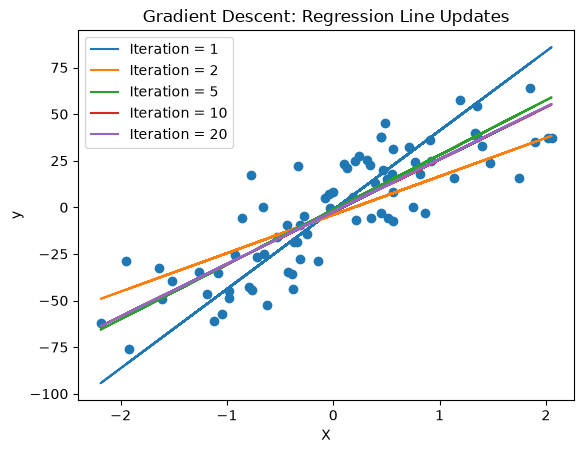

In [28]:
plt.scatter(X_train,y_train)

for i in [0,1,4,9,19]:

    m,b = gd.history[i]

    y_line = m * X_train.ravel() + b

    plt.plot(X_train, y_line, label=f'Iteration = {i+1}')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Gradient Descent: Regression Line Updates')
plt.legend()
plt.show()

# Both algorithms show same values like coefficient,intercept and r2_score are same.